# Tutorial 3: Matrix-free Discontinuous Galerkin single-level solver on a regular grid


This tutorial runs through the steps that we perform to write a single-level DG solver on a regular grid. We implement the standard "benchmark" for this type of solvers, which is solving the Poisson equation on the unit square. All sources for this can be found in tests/multigrid/matrixfree/poisson/dg.py, as the solver is routinely used to do convergence measurements. While we follow some steps of this script, the test Python script has more technical flavours/details which we omit in the notebook. Therefore, it is reasonable to study the present text in combination with the actual script once you've done the notebook once. 

The notebook clarifies how to construct an MGHyPE project with one solver of the type multigrid.matrixfree.solvers.api.DiscontinuousGalerkinDiscretisationPointWiseRiemannSolver
(cmp multigrid/matrixfree/solvers/api/DiscontinuousGalerkinDiscretisationPointWiseRiemannSolver.py in src).
 
Since we solve the Poisson equation, and employ a Discontinuous Galerkin formalism with a point-wise Riemann solver, we start from
 
$$ \mathcal{L}(u) = - \Delta u = f $$
 
 and apply a weak formulation:
 
$$ \begin{eqnarray}
 \int \left( - \Delta u, v \right) dx & = & \int (f, v) dx \\
 \int _c \left( \nabla u, \nabla v \right) dx - \sum _f \int _f \left( \nabla u, n \right) v dS(x) & = & \int (f, v) dx \\
 \int _c \left( \nabla u, \nabla v \right) dx - \sum _f \int _f \left( \mathcal{R}(u^-,u^+), n \right) \phi dS(x) & = & \int (f,v) dx.
 \end{eqnarray}
$$

@todo Alex can you add something on the numerical flux employed and fix the equations above? I think we can copy n paste from the paper draft.

Before we start, we assume that you have either set

or you invoke

In [12]:
import sys, os
 
sys.path.insert(0, os.path.abspath("../../../python/"))
sys.path.insert(0, os.path.abspath("../../../src/"))


We create an MGHyPE project (bear in mind that we basically discuss how to write the test case in the repo; we'd likely use a different namespace otherwise):

In [13]:
import mghype

project = mghype.matrixfree.api.Project( project_name = "Tutorial03", 
                                         namespace = [ "tutorials", "mghype", "examples" ],
                                         executable = "tutorial03",
                                        )


Peano 4 (C) www.peano-framework.org
ParaView is not available, not loading peano4.api.visualisation.
Peano 4 - Multigrid extension


/home/tobias/git/Peano/src/mghype/api/matrixgenerators/GaussLobatto.py:147: SyntaxWarning: invalid escape sequence '\c'
  '''
/home/tobias/git/Peano/src/mghype/api/matrixgenerators/GaussLobatto.py:255: SyntaxWarning: invalid escape sequence '\c'
  """!
/home/tobias/git/Peano/src/mghype/matrixfree/solvers/api/actionsets/DGCGCoupling.py:404: SyntaxWarning: invalid escape sequence '\m'
  """!
/home/tobias/git/Peano/src/mghype/matrixfree/solvers/api/CollocatedDLinearDiscretisationWithPointJacobi.py:17: SyntaxWarning: invalid escape sequence '\d'
  """!
/home/tobias/git/Peano/src/mghype/matrixfree/solvers/api/actionsets/PlotVertexDataInPeanoBlockFormat.py:17: SyntaxWarning: invalid escape sequence '\p'
  """!
/home/tobias/git/Peano/src/mghype/matrixfree/solvers/api/DiscontinuousGalerkinDiscretisationPointWiseRiemannSolver.py:17: SyntaxWarning: invalid escape sequence '\p'
  """!
/home/tobias/git/Peano/src/mghype/matrixfree/solvers/api/DiscontinuousGalerkinDiscretisationPointWiseRiemannSolve

## Create this new solver

The solver construction also is a "one-liner" using the following observations:

- We solve a scalar equation system. Consequently, we have only one unknown per cell node.
- For our numerical flux, we'll need two unknowns per node on the face: One holds the solution and one the gradient. The face will have to hold that info from the left and right side, but MGHyPE takes care of that.


In [15]:
dimensions = 2
polynomial_degree = 5
mesh_size = 0.1
omega_c = 0.5
omega_f = 1.0

solver_name = "DGHigherOrderPoisson"

In [4]:
unknowns_per_cell_node = 1     # scalar PDE
solutions_per_face_node = 2   # We use the penalty formulation (see numerics discussion in tutorials)
projections_per_face_node = 2  # residual plus diagonal value

matrices = mghype.api.matrixgenerators.GLMatrixFree(
  dimensions,
  polynomial_degree,
  unknowns_per_cell_node,
  solutions_per_face_node,
  projections_per_face_node
)

assembly_matrix, assembly_matrix_scaling = matrices.get_cell_system_matrix_for_laplacian()
mass_matrix, mass_matrix_scaling         = matrices.get_cell_mass_matrix()
face_from_cell_projection, \
face_from_cell_projection_scaling        = matrices.get_face_from_cell_matrix()
cell_from_face_projection, \
cell_from_face_projection_scaling        = matrices.get_cell_from_face_matrix()
approximate_system_matrix, \
approximate_system_matrix_scaling        = matrices.get_A_tilde()
integration_points                       = matrices.get_integration_points_over_unit_interval()


solver = mghype.matrixfree.solvers.api.DiscontinuousGalerkinDiscretisationPointWiseRiemannSolver(
  name = solver_name,
  dimensions = dimensions,
  poly_degree = polynomial_degree,
  unknowns_per_cell_node = 1,
  solutions_per_face_node = 2,
  projections_per_face_node = 2,
  min_h = mesh_size,
  max_h = mesh_size,
  assembly_matrix= assembly_matrix, 
  assembly_matrix_scaling = assembly_matrix_scaling, 
  mass_matrix = mass_matrix, 
  mass_matrix_scaling = mass_matrix_scaling, 
  face_from_cell_projection = face_from_cell_projection, 
  face_from_cell_projection_scaling = face_from_cell_projection_scaling,
  cell_from_face_projection = cell_from_face_projection, 
  cell_from_face_projection_scaling = cell_from_face_projection_scaling,
  riemann_matrix = matrices.get_face_face_riemann_problem_matrix(),
  boundary_matrix = matrices.get_boundary_matrix(),
  cell_relaxation = omega_c,
  face_relaxation = omega_f,
  approximate_system_matrix = approximate_system_matrix,
  approximate_system_matrix_scaling = approximate_system_matrix_scaling,
  solver_tolerance = 1e-8,
  integration_points = integration_points,
  custom_init_cell = "rhs(0) = tutorials::mghype::examples::getPointWiseRhs(x);",
  solver_includes = """
#include "Scenario.h"
"""
)


This code block employs MGHyPE's matrix generator quite heavily. It makes sense to consult this class' documentation for further info. There's one more difference and that is that we inject the construction of the right-hand side. Previously, we wrote that ourselves within the generated C++ code. This time, we skip this step and directly inject a C++ code snippet into the generation. However, this code snippet doesn't implement anything itself but calls another function which we still have to define. We discuss this below when we lower the code. 

We next add this solver to the project and set some global parameters:

In [5]:
import peano4.api

project.add_solver(solver)

build_mode = peano4.api.output.CompileMode.Release

cube_size = 1.0
project.set_global_simulation_parameters(
  dimensions            = dimensions,
  offset                = [ 0.0       for _ in range(dimensions) ],
  domain_size           = [ cube_size for _ in range(dimensions) ],
  plot_after_each_mesh_sweep  = False,
)

project.set_load_balancing( "toolbox::loadbalancing::RecursiveSubdivision", "new ::exahype2::LoadBalancingConfiguration()" )
project.set_Peano4_installation( "../../..", build_mode )


---------------------------------------
Create data for solver DGPoisson
---------------------------------------


## Lower into C++ and add bespoke initial values from external file

In line with the hitchhiker's guide, we now lower this into a Peano project and make the latter dump the C++ code. There's now one more thing that we do differently compared with previous tutorials as we announced above: This time, we outsource the actual scenario (aka right-hand side) into a C++ file of its own, include it into the build and then make the solver link to this predefined scenario. I personally think that it is always a good idea to move as much out of the Python or generated environment as possible. With the separate implementation, we can use this right-hand side in different solver flavours or test it separatedly. Obviously, as it is so simple, this is all quite some over-engineering. But for more complex setups, it absolutely makes sense. 

In [6]:
peano4_project = project.generate_Peano4_project(False)
peano4_project.output.makefile.add_cpp_file( "Scenario.cpp" )
peano4_project.generate()

parse configure outcome ../../../config.log to extract configure settings
parse configure outcome ../../../src/Makefile to extract compile settings


AttributeError: 'Project' object has no attribute 'dictionary'

The only "new" thing here's the line add_cpp_file() which we discuss next.

## Compile

Nothing new here compared to previous exercises: 

In [1]:
!make -j8

icpx    Scenario.o  AbstractDGHigherOrderPoisson.o DGHigherOrderPoisson.o repositories/SolverRepository.o celldata/DGHigherOrderPoisson.o facedata/DGHigherOrderPoisson.o vertexdata/DGHigherOrderPoisson.o repositories/DataRepository.o observers/CreateGrid2peano4_toolbox_CreateRegularGrid0.o observers/CreateGrid.o observers/InitSolution2mghype_matrixfree_solvers_api_actionsets_DGSolver_InitDofs0.o observers/InitSolution.o observers/Solve2mghype_matrixfree_solvers_api_actionsets_DGSolver_UpdateFaceSolution_UpdateFaceSolution0.o observers/Solve2mghype_matrixfree_solvers_api_actionsets_DGSolver_ProjectIntoCellAndUpdateCellSolution_ProjectIntoCellAndUpdateCellSolution1.o observers/Solve2mghype_matrixfree_solvers_api_actionsets_DGSolver_ProjectOntoFaces_ProjectOntoFaces2.o observers/Solve2mghype_matrixfree_solvers_api_actionsets_DGSolver_UpdateResidual_UpdateResidual3.o observers/Solve.o observers/Plot2mghype_matrixfree_solvers_api_actionsets_PlotDGDataInPeanoBlockFormat0.o observers/Plot2mgh

If you study this compile call carefull, you will recognise that Peano now has added Solution.cpp to the compile and the linker. Therefore, this project builds with an "external" object file. 

## Run

In [2]:
!rm *.peano-patch-file
!./tutorial03 > tutorial03.out
!cat tutorial03.out

rm: cannot remove '*.peano-patch-file': No such file or directory
 15131861276  00:00:15     rank:0       core:5       warning      tarch::logging::Statistics::writeToCSV(string)          no statistics available. Recompile with -DTrackStatistics for runtime sampling (file:tarch/logging/Statistics.cpp,line:265)
Peano 4 (C) www.peano-framework.org
build: 2d, no mpi, omp (8 threads), no gpu support
 10771        00:00:00     rank:0       core:2       info         ::step()                                                run CreateGrid
 7748001      00:00:00     rank:0       core:2       info         peano4::grid::Spacetree::traverse(...)                  got 1 grid control events: (refinementControl=Refine,offset=[-2.99616e+307,-2.99616e+307],width=[8.98847e+307,8.98847e+307],h=[0.1,0.1])
 1935325      00:00:00     rank:0       core:2       info         ::step()                                                run CreateGrid
 9192293      00:00:00     rank:0       core:1       info         pe

## In-situ visualisation

In this notebook, we convert the outcome in-situ and display it. Obviously, you can do all of this on the command line as well:

In [16]:
import subprocess
import os
my_env = os.environ
my_env["PYTHONPATH"] = "../../../python:" + my_env["PYTHONPATH"]
subprocess.call(["pvpython", "../../../python/peano4/visualisation/render.py", "--filter-fine-grid", "--shrink-cells", "0.9", solver_name + ".rhs.peano-patch-file"], env=my_env)
subprocess.call(["pvpython", "../../../python/peano4/visualisation/render.py", "--filter-fine-grid", "--shrink-cells", "0.9", solver_name + ".solution.peano-patch-file"], env=my_env)

Peano 4 (C) www.peano-framework.org
add fine grid filter
add shrink patches filter
Process snapshot 0
Reading DGHigherOrderPoisson.rhs-0.peano-patch-file as subdomain 0
Error: was not able to read DGHigherOrderPoisson.rhs-0.peano-patch-file: operands could not be broadcast together with shapes (72,) (0,)  in line 
apply filter Filter: ShrinkPatches, run on individual pieces of data=True, run on concatenated data=False, verbose=False to snapshot
Total number of patches: 729
Parsing complete. Convert set of 729 patches with 1 unknowns per 6^2 patch/cell into VTK data structures
apply filter Filter: ExtractFineGrid, run on individual pieces of data=False, run on concatenated data=True, verbose=False
... 10%
... 20%
... 30%
... 40%
... 50%
... 60%
... 70%
... 80%
... 90%
Timestamp for current snapshot: 0.0
Wrote file ./DGHigherOrderPoisson.rhs.peano-patch-file-0.vtu
Process snapshot 1
Reading DGHigherOrderPoisson.rhs-1.peano-patch-file as subdomain 0
Error: was not able to read DGHigherOrd

0

The outcome is not surprising compared to the previous detail. Just one thing to note: We have used the shrink option for the conversion above. This option slightly downscales each individual patch, and it allows us to illustrate more clearly that we are indeed working with a DG scheme as opposed to a continuous approach as we have used it before:

In [6]:
import sys
!{sys.executable} -m pip install --break-system-packages pyvista[all]

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.2 -> 24.3.1
[notice] To update, run: pip install --upgrade pip


In [8]:
import pyvista
mesh = pyvista.read( solver_name + ".rhs.pvd" )
mesh.plot()

Widget(value='<iframe src="http://localhost:34845/index.html?ui=P_0x7f1efe051550_0&reconnect=auto" class="pyvi…

In [9]:
plotter = pyvista.Plotter()
mesh = pyvista.read( solver_name + ".solution.peano-patch-file-1.vtu" )
plotter.add_mesh(mesh, show_edges=True ) # , clim=[0.0, 0.01]
plotter.show()

Widget(value='<iframe src="http://localhost:34845/index.html?ui=P_0x7f1ef200fe00_1&reconnect=auto" class="pyvi…

## Convergence behaviour

And once again the convergence behaviour:

In [17]:
res_max, res_2, res_h = mghype.api.postprocessing.parse_residuals( "tutorial03.out", solver_name )
du_max, du_2, du_h = mghype.api.postprocessing.parse_solution_updates( "tutorial03.out", solver_name )

<>:3: SyntaxWarning: invalid escape sequence '\d'
<>:3: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_73242/420960741.py:3: SyntaxWarning: invalid escape sequence '\d'
  plt.plot(du_2,    label='$|\delta u|_2$',  marker='>')


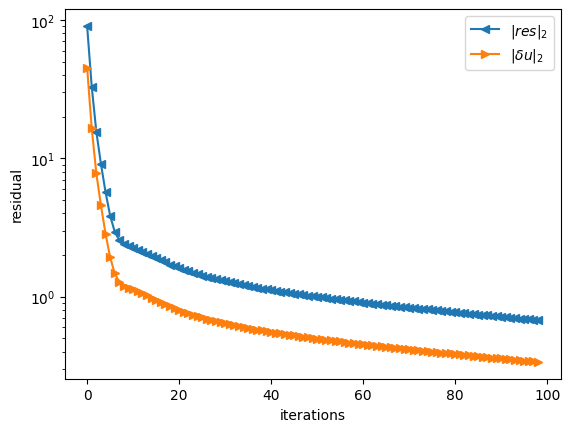

In [18]:
import matplotlib.pyplot as plt
plt.plot(res_2,   label='$|res|_2$',       marker='<')
plt.plot(du_2,    label='$|\delta u|_2$',  marker='>')
#plt.plot(res_max, label='$|res|_{max}$', marker='>')
#plt.plot(res_h,   label='$|res|_h$',     marker='v')
plt.yscale('log')
plt.xlabel('iterations')
plt.ylabel('residual')
plt.legend()
plt.savefig( "tutorial02.pdf" )
plt.savefig( "tutorial02.png" )
plt.show()
